# Ранний отбор обучающих изображений

Проверка статьи [Deep Learning on a Data Diet](https://arxiv.org/abs/2107.07075v2), исправленная версия 2023 года. Сравниваются два набора по 25 000 изображений: случайный отбор и отбор методом статьи. Итоговый вывод появится только после всех восьми обучений.

**Обучающая выборка** — изображения, по которым сеть учится. **Проверочная выборка** — отдельные изображения для оценки точности. **Точность** — доля правильных ответов. CIFAR-10 содержит 50 000 обучающих и 10 000 проверочных изображений размером 32 × 32 пикселя, разделённых на десять классов.

**Оценка ошибки вероятностей (EL2N)** — расстояние между предсказанными вероятностями классов и вектором правильного ответа. У правильного класса в этом векторе стоит единица, у остальных — нули. Сначала обучаются десять сетей; затем для каждого изображения усредняются десять расстояний. Для итогового обучения сохраняются 25 000 изображений с наибольшей средней оценкой.

**Шаг обучения** — одно обновление весов по 128 изображениям. Предварительная сеть проходит 7 800 шагов, итоговая — 78 000. **Эпоха** — проход по выборке; 390 шагов соответствуют почти одному проходу по полному набору. Поэтому одинаковые 78 000 шагов дают около 400 проходов по половине данных. Четыре повторения каждого способа используют попарно одинаковые начальные веса.

По умолчанию выполняются проверка сохранённых измерений и построение графиков. Для обучения с нуля выберите Colab с T4 и установите `RUN_TRAINING = True`. Программа и архитектура включены в этот блокнот. После завершения процесса снова выполните раздел анализа. При восстановлении перенесите `hw2_restore.zip` в панель «Файлы» Colab и укажите его путь ниже.

In [1]:
from pathlib import Path
import sys
RUN_TRAINING = False
RESTORE_ARCHIVE = None  # Например: "/content/hw2_restore.zip".
IN_COLAB = 'google.colab' in sys.modules
WORK = Path('/content') if IN_COLAB else Path.cwd()
TRAIN_RESULTS = WORK/'Efficient_NN_HW2_CIFAR10_T4_half25k'
ROOT = TRAIN_RESULTS if RUN_TRAINING else Path('results')


## Сохранённые измерения

In [2]:
import hashlib, json, urllib.request, zipfile
if not RUN_TRAINING:
    snapshot = Path('results_snapshot.zip')
    if not snapshot.exists():
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Mixlazer/Efficient-NN-HW-2/main/hw2/results_snapshot.zip', snapshot)
    assert hashlib.sha256(snapshot.read_bytes()).hexdigest() == '5868e514db1895a50e18ea48fe17acaa13b2c35c8e27bb6e917c79c05bb3557d', 'Версия данных не совпала с блокнотом.'
    with zipfile.ZipFile(snapshot) as bundle:
        manifest = json.loads(bundle.read('file_manifest.json'))
        for entry in manifest:
            raw=bundle.read(entry['path'])
            assert len(raw)==entry['bytes'] and hashlib.sha256(raw).hexdigest()==entry['sha256']
            destination=ROOT/entry['path']
            assert destination.resolve().is_relative_to(ROOT.resolve())
            destination.parent.mkdir(parents=True,exist_ok=True)
            destination.write_bytes(raw)
    print('Сохранённые данные прошли проверку контрольных сумм.')


Сохранённые данные прошли проверку контрольных сумм.


## Результат авторов

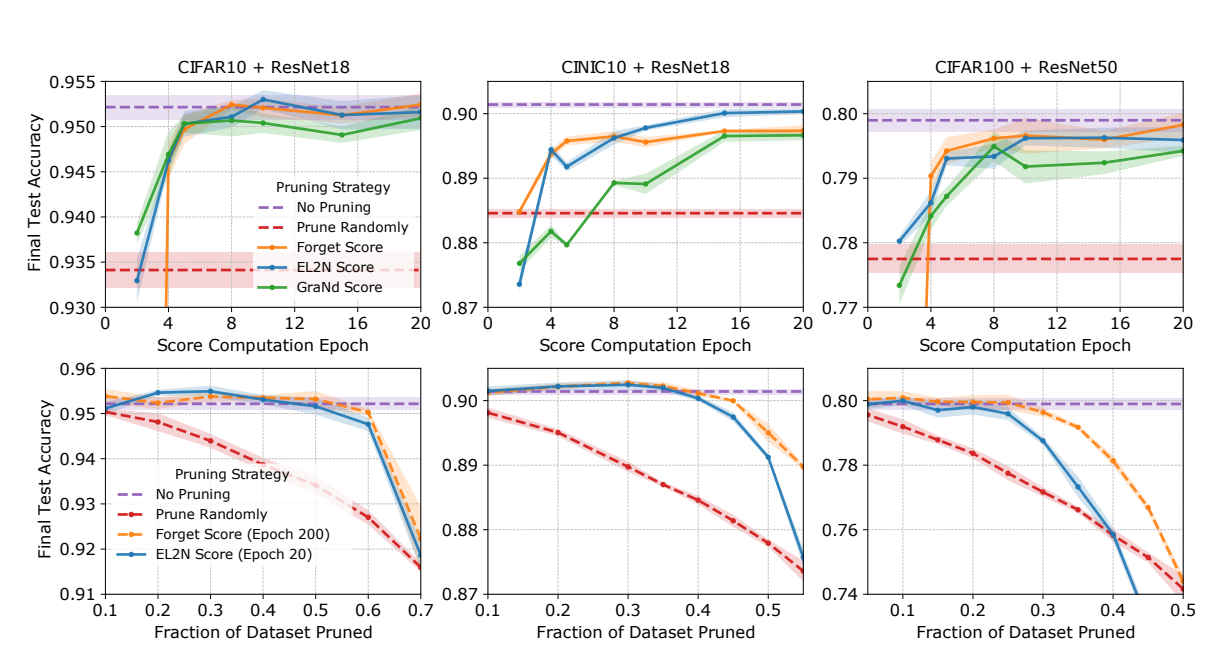

Рисунок 1 оригинальной статьи. Первый столбец относится к CIFAR-10 и ResNet-18 — сети с восемнадцатью слоями и связями между блоками. Верхний график связывает итоговую точность с моментом оценки изображений, нижний — с долей удалённых данных. Это измерения авторов, а не результаты данного опыта.

In [3]:
from IPython.display import display, Image, Markdown
if not RUN_TRAINING:
    display(Image(filename=str(ROOT/'article_figure_01.png')))
    display(Markdown('Рисунок 1 оригинальной статьи. Первый столбец относится к CIFAR-10 и ResNet-18 — сети с восемнадцатью слоями и связями между блоками. Верхний график связывает итоговую точность с моментом оценки изображений, нижний — с долей удалённых данных. Это измерения авторов, а не результаты данного опыта.'))


## Обучение в Google Colab

Архитектура сохранена без изменений из [версии авторского кода](https://github.com/mansheej/data_diet/tree/aee462eab93aa0fb14c1ddfeba45d645b85a5fbb); лицензия Apache 2.0 прилагается. Используются современные JAX и Flax — библиотеки вычислений и описания сети. Отличия: другие версии библиотек, порядок исходных изображений и генераторы случайного перемешивания. Формула обновления весов, преобразования изображений и число шагов сохранены. Итоговой сети на всех 50 000 изображениях нет: это ограниченная проверка сравнения способов отбора.

In [4]:
if RUN_TRAINING:
    assert IN_COLAB, 'Обучение этого опыта выполняется в Google Colab.'
    import subprocess, importlib.metadata
    gpu=subprocess.check_output(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],text=True)
    assert 'T4' in gpu, 'Выберите Tesla T4.'
    packages={'jax':'0.11.1','flax':'0.12.10','numpy':'2.1.3','torch':'2.11.0','torchvision':'0.26.0'}
    missing=[f'{name}=={version}' for name,version in packages.items()
             if importlib.metadata.version(name).split('+')[0]!=version]
    if missing:
        missing=['jax[cuda13]==0.11.1' if item.startswith('jax==') else item for item in missing]
        subprocess.run([sys.executable,'-m','pip','install','-q',*missing],check=True)
    print('Ускоритель:',gpu.strip())


In [5]:
PROGRAM = r'''"""Сравнение двух способов отбора половины CIFAR-10 в Google Colab T4.

Архитектура берётся без изменений из sources/author_models.py (Apache-2.0).
Современный цикл обучения заменяет устаревший интерфейс flax.optim.
"""
import argparse
import hashlib
import importlib.util
import json
import os
from pathlib import Path
import platform
import shutil
import tempfile
import time
import urllib.request

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip()
import jax
import jax.numpy as jnp
import flax
from flax import serialization
import numpy as np
from torchvision.datasets import CIFAR10

ROOT = Path(__file__).resolve().parent
MODEL_PATH = ROOT / "sources/author_models.py"
MODEL_SHA = "92123c6a912d3ee4a2ef5b95b37fac5cea0bc25ff240c19c6b7af71534523201"
assert hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest() == MODEL_SHA
spec = importlib.util.spec_from_file_location("author_models", MODEL_PATH)
author_models = importlib.util.module_from_spec(spec)
spec.loader.exec_module(author_models)
MODEL = author_models.ResNet18(num_classes=10, lowres=True)
BATCH, EPOCH_STEPS = 128, 390
CONFIG = dict(dataset="CIFAR-10", train_size=50000, test_size=10000,
    architecture="author ResNet18 lowres, float32", batch_size=BATCH,
    train_steps=78000, score_steps=7800, score_runs=10, eval_runs=4,
    retained_fraction=0.5, learning_rate=0.1, momentum=0.9,
    nesterov=True, weight_decay=0.0005, decay_steps=[23400, 46800, 62400],
    decay_factor=0.2, author_commit="aee462eab93aa0fb14c1ddfeba45d645b85a5fbb",
    model_sha256=MODEL_SHA,
    normalization_mean=[0.4914, 0.4822, 0.4465],
    normalization_std=[0.2470, 0.2435, 0.2616],
    augmentation="reflect padding 4, shared batch crop, independent horizontal flips",
    deterministic_gpu_operations=True,
    score_run_ids=list(range(10)), evaluation_run_ids=list(range(10, 14)),
    evaluation_methods=["random", "el2n"],
    differences=["Modern JAX/Flax instead of historical package versions",
        "Canonical CIFAR Python order, then stable class sort, instead of TFDS order",
        "NumPy shuffle and JAX augmentation randomness instead of JAX shuffle and TensorFlow randomness",
        "Test set evaluated only after training; no choice of best test checkpoint",
        "Full-data baseline omitted at user request; two subsets of 25000 images compared"])


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)


def el2n(probabilities, labels):
    return jnp.linalg.norm(probabilities - jax.nn.one_hot(labels, 10), axis=-1)


def initial_state(run_id):
    variables = MODEL.init(jax.random.PRNGKey(42 + 424242 * run_id),
                           jnp.ones((1, 32, 32, 3), jnp.float32))
    return dict(params=variables["params"], batch_stats=variables["batch_stats"],
                momentum=jax.tree.map(jnp.zeros_like, variables["params"]))


def learning_rate(step):
    # В авторском цикле первый шаг имеет номер 1.
    return 0.1 * 0.2 ** jnp.sum(step + 1 >= jnp.array(CONFIG["decay_steps"]))


def update_parameters(params, momentum, gradients, rate):
    gradients = jax.tree.map(lambda g, p: g + 0.0005 * p, gradients, params)
    momentum = jax.tree.map(lambda m, g: 0.9 * m + g, momentum, gradients)
    params = jax.tree.map(lambda p, g, m: p - rate * (g + 0.9 * m),
                          params, gradients, momentum)
    return params, momentum


def train_step(state, images, labels, key, step):
    crop_key, flip_key = jax.random.split(key)
    offset = jax.random.randint(crop_key, (2,), 0, 9)
    padded = jnp.pad(images, ((0, 0), (4, 4), (4, 4), (0, 0)), mode="reflect")
    images = jax.lax.dynamic_slice(padded, (0, offset[0], offset[1], 0), (BATCH, 32, 32, 3))
    flip = jax.random.bernoulli(flip_key, 0.5, (BATCH, 1, 1, 1))
    images = jnp.where(flip, images[:, :, ::-1, :], images)

    def loss_fn(params):
        logits, updates = MODEL.apply(dict(params=params, batch_stats=state["batch_stats"]),
            images, train=True, mutable=["batch_stats"])
        loss = -jnp.mean(jnp.take_along_axis(jax.nn.log_softmax(logits), labels[:, None], axis=1))
        return loss, updates["batch_stats"]

    (loss, batch_stats), gradients = jax.value_and_grad(loss_fn, has_aux=True)(state["params"])
    params, momentum = update_parameters(state["params"], state["momentum"], gradients, learning_rate(step))
    return dict(params=params, batch_stats=batch_stats, momentum=momentum), loss


@jax.jit
def train_chunk(state, images, labels, index_rows, first_step, seed):
    def body(current, item):
        offset, indices = item
        step = first_step + offset
        key = jax.random.fold_in(jax.random.PRNGKey(seed), step)
        return train_step(current, images[indices], labels[indices], key, step)
    return jax.lax.scan(body, state, (jnp.arange(index_rows.shape[0]), index_rows))


@jax.jit
def predict(state, images):
    logits = MODEL.apply(dict(params=state["params"], batch_stats=state["batch_stats"]),
                         images, train=False)
    return jax.nn.softmax(logits)


def batches(indices, step, count, seed):
    """Порядок зависит только от номера шага: продолжение не меняет случайные числа."""
    length = len(indices) // BATCH
    rows, previous_cycle, permutation = [], None, None
    for number in range(step, step + count):
        cycle, offset = divmod(number, length)
        if cycle != previous_cycle:
            permutation = np.random.default_rng(np.random.SeedSequence([seed, cycle])).permutation(indices)
            previous_cycle = cycle
        rows.append(permutation[offset * BATCH:(offset + 1) * BATCH])
    return np.asarray(rows, dtype=np.int32)


def load_data(directory):
    directory.mkdir(parents=True, exist_ok=True)
    archive = directory / "cifar-10-python.tar.gz"
    if not archive.exists() or hashlib.md5(archive.read_bytes()).hexdigest() != "c58f30108f718f92721af3b95e74349a":
        url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/a48007227f9e2cd0af96175f4afb5ac4965e261b/cifar-10-python.tar.gz"
        print("Загружаю официальный архив CIFAR-10 с зеркала; затем проверяю контрольную сумму.", flush=True)
        urllib.request.urlretrieve(url, archive.with_suffix(".download"))
        assert hashlib.md5(archive.with_suffix(".download").read_bytes()).hexdigest() == "c58f30108f718f92721af3b95e74349a"
        archive.with_suffix(".download").replace(archive)
    train = CIFAR10(str(directory), train=True, download=True)
    test = CIFAR10(str(directory), train=False, download=True)
    labels = np.asarray(train.targets, dtype=np.int32)
    order = np.argsort(labels, kind="stable")
    mean = np.asarray(CONFIG["normalization_mean"], np.float32) * 255
    std = np.asarray(CONFIG["normalization_std"], np.float32) * 255
    normalize = lambda data: (data.astype(np.float32) - mean) / std
    return (jax.device_put(normalize(train.data[order])), jax.device_put(labels[order]),
            jax.device_put(normalize(test.data)), np.asarray(test.targets, np.int32), order)


def checkpoint(path, state, step, seconds, run_id, condition, config_hash):
    value = dict(state=jax.device_get(state), step=int(step), seconds=float(seconds),
                 run_id=run_id, condition=condition, config_hash=config_hash)
    temporary = path.with_suffix(".tmp")
    temporary.write_bytes(serialization.msgpack_serialize(value))
    temporary.replace(path)


def train_one(folder, run_id, condition, indices, steps, images, labels, config_hash):
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / "checkpoint.msgpack"
    state, step, seconds = initial_state(run_id), 0, 0.0
    if path.exists():
        saved = serialization.msgpack_restore(path.read_bytes())
        assert (saved["config_hash"], saved["run_id"], saved["condition"]) == (config_hash, run_id, condition)
        state, step, seconds = jax.device_put(saved["state"]), saved["step"], saved["seconds"]
        print(f"Продолжаю {folder.name}: шаг {step} из {steps}.", flush=True)
    np.save(folder / "selected_sorted_indices.npy", indices)
    started, initial_seconds = time.perf_counter(), seconds
    losses = []
    while step < steps:
        count = min(10, steps - step, EPOCH_STEPS - step % EPOCH_STEPS)
        rows = batches(indices, step, count, 4242 + 424242 * run_id)
        state, chunk_losses = train_chunk(state, images, labels, rows,
            np.int32(step), np.int32(4242 + 424242 * run_id))
        chunk_losses = np.asarray(chunk_losses)
        if not np.isfinite(chunk_losses).all():
            raise RuntimeError(f"Нечисловое значение ошибки обучения: {folder.name}, шаг {step}")
        losses.extend(chunk_losses.tolist())
        step += count
        if step % EPOCH_STEPS == 0 or step == steps:
            seconds = initial_seconds + time.perf_counter() - started
            record = dict(step=step, equivalent_epoch=step / EPOCH_STEPS,
                train_loss=float(np.mean(losses)), seconds=seconds,
                learning_rate=float(learning_rate(step - 1)))
            with (folder / "history.jsonl").open("a", encoding="utf-8") as handle:
                handle.write(json.dumps(record) + "\n")
            losses.clear()
            print(f"{folder.name}: эпоха {step / EPOCH_STEPS:g}; "
                  f"ошибка {record['train_loss']:.4f}; прошло {seconds / 60:.1f} мин.", flush=True)
            write_json(folder.parent / "progress.json", dict(run=folder.name, **record))
            if step % (5 * EPOCH_STEPS) == 0 or step == steps:
                checkpoint(path, state, step, seconds, run_id, condition, config_hash)
    return state, seconds


def probabilities(state, images):
    result = []
    for start in range(0, len(images), 256):
        chunk = images[start:start + 256]
        size = len(chunk)
        # Последнюю порцию дополняем, чтобы повторно не компилировать сеть.
        chunk = jnp.pad(chunk, ((0, 256-size), (0, 0), (0, 0), (0, 0)))
        result.append(np.asarray(predict(state, chunk))[:size])
    return np.concatenate(result)


def summarize(folder):
    rows = [json.loads(p.read_text()) for p in sorted(folder.glob("evaluate_*/metrics.json"))]
    result = []
    for method in CONFIG["evaluation_methods"]:
        subset = [row for row in rows if row["method"] == method]
        if not subset:
            continue
        accuracy = np.array([row["accuracy"] for row in subset])
        result.append(dict(method=method, completed=len(subset), required=CONFIG["eval_runs"],
            mean=float(accuracy.mean()), std=float(accuracy.std(ddof=1)) if len(subset)>1 else None,
            p16=float(np.quantile(accuracy, .16)), p84=float(np.quantile(accuracy, .84))))
    expected = {(run_id, method) for run_id in CONFIG["evaluation_run_ids"]
                for method in CONFIG["evaluation_methods"]}
    actual = {(row["run_id"], row["method"]) for row in rows}
    complete = actual == expected and len(rows) == len(expected)
    write_json(folder / "summary.json", dict(complete=complete, runs=rows, summary=result))
    return result


def import_score_checkpoint(source, output, config_hash):
    """Явный перенос только проверенного предварительного сохранения; исходник остаётся целым."""
    target = output / "score_00" / "checkpoint.msgpack"
    if target.exists():
        return
    previous_sha = "edb6e126fbd793a7e487e907d317a3ab16d7d26e2d4da29d258f5c8ddbfe424d"
    previous = json.loads((source / "config.json").read_text())
    expected = dict(CONFIG, source_sha256=previous_sha)
    expected.pop("evaluation_methods")
    expected["differences"] = CONFIG["differences"][:-1]
    assert previous == expected, "Прежние настройки предварительного обучения отличаются."
    assert hashlib.sha256((source / "colab_reproduce.py").read_bytes()).hexdigest() == previous_sha
    old_hash = hashlib.sha256(json.dumps(previous, sort_keys=True).encode()).hexdigest()
    raw = (source / "score_00" / "checkpoint.msgpack").read_bytes()
    saved = serialization.msgpack_restore(raw)
    assert (saved["config_hash"], saved["run_id"], saved["condition"], saved["step"]) == (old_hash, 0, "score", 3900)
    assert np.array_equal(np.load(source / "score_00" / "selected_sorted_indices.npy"), np.arange(50000))
    target.parent.mkdir(parents=True, exist_ok=True)
    write_json(output / "checkpoint_import.json", dict(source=str(source), source_sha256=previous_sha,
        checkpoint_sha256=hashlib.sha256(raw).hexdigest(), old_config_hash=old_hash,
        new_config_hash=config_hash, step=3900,
        reason="Предварительное обучение не изменено; исключён только итоговый вариант на всей выборке."))
    checkpoint(target, saved["state"], saved["step"], saved["seconds"], 0, "score", config_hash)
    print("Перенесено проверенное предварительное сохранение: шаг 3900.", flush=True)


def run(output, data, reuse_scores_from=None):
    assert any("T4" in device.device_kind for device in jax.devices()), "Нужен ускоритель T4."
    output.mkdir(parents=True, exist_ok=True)
    config = dict(CONFIG, source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest())
    config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
    if (output / "config.json").exists():
        assert json.loads((output / "config.json").read_text()) == config, "Параметры изменены; нужна новая папка результатов."
    write_json(output / "config.json", config)
    environment = dict(python=platform.python_version(), platform=platform.platform(),
        jax=jax.__version__, flax=flax.__version__, numpy=np.__version__,
        devices=[str(device) + " " + device.device_kind for device in jax.devices()])
    with (output / "sessions.jsonl").open("a", encoding="utf-8") as handle:
        handle.write(json.dumps(dict(time=time.time(), **environment)) + "\n")
    shutil.copy2(__file__, output / "colab_reproduce.py")
    shutil.copy2(MODEL_PATH, output / "author_models.py")
    if reuse_scores_from is not None:
        import_score_checkpoint(reuse_scores_from, output, config_hash)
    images, labels, test_images, test_labels, original_order = load_data(data)
    np.save(output / "sorted_to_original_indices.npy", original_order)
    all_indices = np.arange(50000, dtype=np.int32)
    scores = []
    for run_id in CONFIG["score_run_ids"]:
        folder = output / f"score_{run_id:02d}"
        if not (folder / "complete.json").exists():
            state, seconds = train_one(folder, run_id, "score", all_indices, 7800, images, labels, config_hash)
            score = np.asarray(el2n(probabilities(state, images), labels))
            assert score.shape == (50000,) and np.isfinite(score).all()
            np.save(folder / "scores.npy", score)
            write_json(folder / "complete.json", dict(seconds=seconds, steps=7800))
            del state
        scores.append(np.load(folder / "scores.npy"))
    mean_scores = np.stack(scores).mean(axis=0)
    np.save(output / "el2n_scores.npy", mean_scores)
    selected_el2n = np.sort(np.argsort(-mean_scores, kind="stable")[:25000]).astype(np.int32)
    for run_id in CONFIG["evaluation_run_ids"]:
        selections = dict(random=np.sort(np.random.default_rng(100000+run_id).choice(50000, 25000, replace=False)).astype(np.int32),
            el2n=selected_el2n)
        for method, indices in selections.items():
            folder = output / f"evaluate_{run_id:02d}_{method}"
            if (folder / "metrics.json").exists():
                continue
            state, seconds = train_one(folder, run_id, method, indices, 78000, images, labels, config_hash)
            prediction = probabilities(state, test_images)
            correct = int((prediction.argmax(axis=1) == test_labels).sum())
            np.save(folder / "test_probabilities.npy", prediction)
            np.save(folder / "selected_original_indices.npy", original_order[indices])
            record = dict(method=method, run_id=run_id, model_seed=42+424242*run_id,
                train_seed=4242+424242*run_id, steps=78000, train_size=len(indices),
                correct=correct, test_size=10000, accuracy=correct/10000,
                train_seconds=seconds, class_counts=np.bincount(np.asarray(labels)[indices], minlength=10).tolist())
            write_json(folder / "metrics.json", record)
            print(json.dumps(record, ensure_ascii=False), flush=True)
            summarize(output)
            del state
    print("Все 8 итоговых запусков завершены.", flush=True)
    print(json.dumps(summarize(output), ensure_ascii=False, indent=2), flush=True)


def self_check():
    uniform = jnp.full((2, 10), .1)
    assert np.allclose(el2n(uniform, jnp.array([0, 4])), np.sqrt(.9))
    assert np.allclose(el2n(jax.nn.one_hot(jnp.array([0, 4]), 10), jnp.array([0, 4])), 0)
    params, momentum = update_parameters({"x": jnp.array(2.)}, {"x": jnp.array(.3)}, {"x": jnp.array(.4)}, .1)
    gradient = .4 + .0005 * 2
    expected_momentum = .9 * .3 + gradient
    assert np.allclose(params["x"], 2 - .1 * (gradient + .9 * expected_momentum))
    indices = np.arange(500)
    whole = batches(indices, 0, 11, 7)
    assert np.array_equal(whole, np.concatenate([batches(indices, 0, 5, 7), batches(indices, 5, 6, 7)]))
    assert len(np.unique(whole[:3])) == 384
    assert np.allclose([learning_rate(step) for step in [0, 23398, 23399, 46799, 62399]], [.1, .1, .02, .004, .0008])
    with tempfile.TemporaryDirectory() as directory:
        folder = Path(directory)
        for run_id in CONFIG["evaluation_run_ids"]:
            for method in CONFIG["evaluation_methods"]:
                run_folder = folder / f"evaluate_{run_id:02d}_{method}"
                run_folder.mkdir()
                write_json(run_folder / "metrics.json", dict(run_id=run_id, method=method, accuracy=.9))
        summarize(folder)
        assert json.loads((folder / "summary.json").read_text())["complete"]
        (run_folder / "metrics.json").unlink()
        summarize(folder)
        assert not json.loads((folder / "summary.json").read_text())["complete"]
    state = initial_state(99)
    images = jax.random.normal(jax.random.PRNGKey(0), (BATCH, 32, 32, 3))
    labels = jnp.arange(BATCH, dtype=jnp.int32) % 10
    rows = np.tile(np.arange(BATCH), (10, 1)).astype(np.int32)
    state, loss = train_chunk(state, images, labels, rows, np.int32(0), np.int32(7))
    assert np.isfinite(np.asarray(loss)).all()
    restored = jax.device_put(serialization.msgpack_restore(serialization.msgpack_serialize(jax.device_get(state))))
    uninterrupted, _ = train_chunk(state, images, labels, rows, np.int32(10), np.int32(7))
    resumed, _ = train_chunk(restored, images, labels, rows, np.int32(10), np.int32(7))
    assert all(np.array_equal(a, b) for a, b in zip(jax.tree.leaves(uninterrupted), jax.tree.leaves(resumed)))
    start = time.perf_counter()
    for i in range(5):
        state, loss = train_chunk(state, images, labels, rows, np.int32(20 + 10*i), np.int32(7))
    np.asarray(loss)
    seconds = time.perf_counter() - start
    print(json.dumps(dict(checks="passed: score, optimizer, schedule, batch continuation, exact checkpoint continuation",
        benchmark_steps=50, seconds=seconds, seconds_per_step=seconds/50,
        projected_training_hours=(10*7800 + 8*78000)*seconds/50/3600,
        note="Предварительная оценка по искусственным изображениям; это не результат воспроизведения."), ensure_ascii=False, indent=2), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--output", type=Path, default=Path("/content/data_diet_results"))
    parser.add_argument("--data", type=Path, default=Path("/content/cifar10"))
    parser.add_argument("--self-check", action="store_true")
    parser.add_argument("--reuse-scores-from", type=Path,
        help="Перенести проверенное сохранение score_00 после 3900 шагов из прежнего полного опыта.")
    args = parser.parse_args()
    self_check() if args.self_check else run(args.output, args.data, args.reuse_scores_from)
'''
if RUN_TRAINING:
    (WORK/'colab_reproduce.py').write_text(PROGRAM,encoding='utf-8',newline='\n')


In [6]:
if RUN_TRAINING:
    import base64
    (WORK/'sources').mkdir(exist_ok=True)
    (WORK/'sources/author_models.py').write_bytes(base64.b64decode('ZnJvbSBmbGF4IGltcG9ydCBsaW5lbiBhcyBubg0KZnJvbSBmdW5jdG9vbHMgaW1wb3J0IHBhcnRpYWwNCmZyb20gamF4IGltcG9ydCBudW1weSBhcyBqbnANCmZyb20gamF4LnRyZWVfdXRpbCBpbXBvcnQgdHJlZV9mbGF0dGVuDQpmcm9tIHR5cGluZyBpbXBvcnQgQW55LCBDYWxsYWJsZSwgU2VxdWVuY2UsIFR1cGxlDQppbXBvcnQgbnVtcHkgYXMgbnANCg0KDQojIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMNCiMgIFNpbXBsZUNOTg0KIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjDQoNCmNsYXNzIFNpbXBsZUNOTihubi5Nb2R1bGUpOg0KICBudW1fY2hhbm5lbHM6IFNlcXVlbmNlW2ludF0NCiAgbnVtX2NsYXNzZXM6IGludA0KICBkdHlwZTogQW55ID0gam5wLmZsb2F0MzINCg0KICBAbm4uY29tcGFjdA0KICBkZWYgX19jYWxsX18oc2VsZiwgeCwgdHJhaW49RmFsc2UpOiAgIyB0cmFpbiBpcyBhIGR1bW15IGFyZ3VtZW50LCBtb2RlbCBkb2VzIG5vdCBoYXZlIGRpZmZlcmVudCB0cmFpbiBhbmQgZXZhbCBtb2Rlcw0KICAgIGZvciBuYyBpbiBzZWxmLm51bV9jaGFubmVsczoNCiAgICAgIHggPSBubi5Db252KG5jLCAoMywgMyksIHBhZGRpbmc9J1NBTUUnLCBkdHlwZT1zZWxmLmR0eXBlKSh4KQ0KICAgICAgeCA9IG5uLnJlbHUoeCkNCiAgICAgIHggPSBubi5Db252KG5jLCAoMywgMyksICgyLCAyKSwgJ1NBTUUnLCBkdHlwZT1zZWxmLmR0eXBlKSh4KQ0KICAgICAgeCA9IG5uLnJlbHUoeCkNCiAgICB4ID0gam5wLm1lYW4oeCwgYXhpcz0oMSwgMikpDQogICAgeCA9IG5uLkRlbnNlKHNlbGYubnVtX2NsYXNzZXMsIGR0eXBlPXNlbGYuZHR5cGUpKHgpDQogICAgcmV0dXJuIHgNCg0KDQojIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMNCiMgIFJlc05ldDE4OiBiYXNlZCBvbiBmbGF4IGFuZCBlbGVneSBpbXBsZW1lbnRhdGlvbnMgb2YgUmVzTmV0IFYxDQojIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMNCg0KTW9kdWxlRGVmID0gQW55DQoNCg0KY2xhc3MgUmVzTmV0QmxvY2sobm4uTW9kdWxlKToNCiAgIiIiUmVzTmV0IGJsb2NrLiIiIg0KICBmaWx0ZXJzOiBpbnQNCiAgY29udjogTW9kdWxlRGVmDQogIG5vcm06IE1vZHVsZURlZg0KICBhY3Q6IENhbGxhYmxlDQogIHN0cmlkZXM6IFR1cGxlW2ludCwgaW50XSA9ICgxLCAxKQ0KDQogIEBubi5jb21wYWN0DQogIGRlZiBfX2NhbGxfXyhzZWxmLCB4LCk6DQogICAgcmVzaWR1YWwgPSB4DQogICAgeSA9IHNlbGYuY29udihzZWxmLmZpbHRlcnMsICgzLCAzKSwgc2VsZi5zdHJpZGVzKSh4KQ0KICAgIHkgPSBzZWxmLm5vcm0oKSh5KQ0KICAgIHkgPSBzZWxmLmFjdCh5KQ0KICAgIHkgPSBzZWxmLmNvbnYoc2VsZi5maWx0ZXJzLCAoMywgMykpKHkpDQogICAgeSA9IHNlbGYubm9ybSgpKHkpDQoNCiAgICBpZiByZXNpZHVhbC5zaGFwZSAhPSB5LnNoYXBlOg0KICAgICAgcmVzaWR1YWwgPSBzZWxmLmNvbnYoc2VsZi5maWx0ZXJzLCAoMSwgMSksIHNlbGYuc3RyaWRlcywgbmFtZT0nY29udl9wcm9qJykocmVzaWR1YWwpDQogICAgICByZXNpZHVhbCA9IHNlbGYubm9ybShuYW1lPSdub3JtX3Byb2onKShyZXNpZHVhbCkNCg0KICAgIHJldHVybiBzZWxmLmFjdChyZXNpZHVhbCArIHkpDQoNCg0KY2xhc3MgQm90dGxlbmVja1Jlc05ldEJsb2NrKG5uLk1vZHVsZSk6DQogICIiIkJvdHRsZW5lY2sgUmVzTmV0IGJsb2NrLiIiIg0KICBmaWx0ZXJzOiBpbnQNCiAgY29udjogTW9kdWxlRGVmDQogIG5vcm06IE1vZHVsZURlZg0KICBhY3Q6IENhbGxhYmxlDQogIHN0cmlkZXM6IFR1cGxlW2ludCwgaW50XSA9ICgxLCAxKQ0KDQogIEBubi5jb21wYWN0DQogIGRlZiBfX2NhbGxfXyhzZWxmLCB4KToNCiAgICByZXNpZHVhbCA9IHgNCiAgICB5ID0gc2VsZi5jb252KHNlbGYuZmlsdGVycywgKDEsIDEpKSh4KQ0KICAgIHkgPSBzZWxmLm5vcm0oKSh5KQ0KICAgIHkgPSBzZWxmLmFjdCh5KQ0KICAgIHkgPSBzZWxmLmNvbnYoc2VsZi5maWx0ZXJzLCAoMywgMyksIHNlbGYuc3RyaWRlcykoeSkNCiAgICB5ID0gc2VsZi5ub3JtKCkoeSkNCiAgICB5ID0gc2VsZi5hY3QoeSkNCiAgICB5ID0gc2VsZi5jb252KHNlbGYuZmlsdGVycyAqIDQsICgxLCAxKSkoeSkNCiAgICB5ID0gc2VsZi5ub3JtKHNjYWxlX2luaXQ9bm4uaW5pdGlhbGl6ZXJzLnplcm9zKSh5KQ0KDQogICAgaWYgcmVzaWR1YWwuc2hhcGUgIT0geS5zaGFwZToNCiAgICAgIHJlc2lkdWFsID0gc2VsZi5jb252KHNlbGYuZmlsdGVycyAqIDQsICgxLCAxKSwNCiAgICAgICAgICAgICAgICAgICAgICAgICAgIHNlbGYuc3RyaWRlcywgbmFtZT0nY29udl9wcm9qJykocmVzaWR1YWwpDQogICAgICByZXNpZHVhbCA9IHNlbGYubm9ybShuYW1lPSdub3JtX3Byb2onKShyZXNpZHVhbCkNCg0KICAgIHJldHVybiBzZWxmLmFjdChyZXNpZHVhbCArIHkpDQoNCg0KY2xhc3MgUmVzTmV0KG5uLk1vZHVsZSk6DQogICIiIlJlc05ldFYxLiIiIg0KICBzdGFnZV9zaXplczogU2VxdWVuY2VbaW50XQ0KICBibG9ja19jbHM6IE1vZHVsZURlZg0KICBudW1fY2xhc3NlczogaW50DQogIG51bV9maWx0ZXJzOiBpbnQgPSA2NA0KICBsb3dyZXM6IGJvb2wgPSBUcnVlDQogIGR0eXBlOiBBbnkgPSBqbnAuZmxvYXQzMg0KICBhY3Q6IENhbGxhYmxlID0gbm4ucmVsdQ0KDQogIEBubi5jb21wYWN0DQogIGRlZiBfX2NhbGxfXyhzZWxmLCB4LCB0cmFpbjogYm9vbCA9IFRydWUpOg0KICAgIGNvbnYgPSBwYXJ0aWFsKG5uLkNvbnYsIHVzZV9iaWFzPUZhbHNlLCBkdHlwZT1zZWxmLmR0eXBlKQ0KICAgIG5vcm0gPSBwYXJ0aWFsKG5uLkJhdGNoTm9ybSwgdXNlX3J1bm5pbmdfYXZlcmFnZT1ub3QgdHJhaW4sIG1vbWVudHVtPTAuOSwgZXBzaWxvbj0xZS01LCBkdHlwZT1zZWxmLmR0eXBlKQ0KDQogICAgeCA9IGNvbnYoc2VsZi5udW1fZmlsdGVycywNCiAgICAgICAgICAgICAoMywgMykgaWYgc2VsZi5sb3dyZXMgZWxzZSAoNywgNyksDQogICAgICAgICAgICAgKDEsIDEpIGlmIHNlbGYubG93cmVzIGVsc2UgKDIsIDIpLA0KICAgICAgICAgICAgIHBhZGRpbmc9J1NBTUUnLA0KICAgICAgICAgICAgIG5hbWU9J2NvbnZfaW5pdCcpKHgpDQogICAgeCA9IG5vcm0obmFtZT0nYm5faW5pdCcpKHgpDQogICAgeCA9IG5uLnJlbHUoeCkNCiAgICBpZiBub3Qgc2VsZi5sb3dyZXM6DQogICAgICB4ID0gbm4ubWF4X3Bvb2woeCwgKDMsIDMpLCBzdHJpZGVzPSgyLCAyKSwgcGFkZGluZz0nU0FNRScpDQogICAgZm9yIGksIGJsb2NrX3NpemUgaW4gZW51bWVyYXRlKHNlbGYuc3RhZ2Vfc2l6ZXMpOg0KICAgICAgZm9yIGogaW4gcmFuZ2UoYmxvY2tfc2l6ZSk6DQogICAgICAgIHN0cmlkZXMgPSAoMiwgMikgaWYgaSA+IDAgYW5kIGogPT0gMCBlbHNlICgxLCAxKQ0KICAgICAgICB4ID0gc2VsZi5ibG9ja19jbHMoc2VsZi5udW1fZmlsdGVycyAqIDIgKiogaSwgc3RyaWRlcz1zdHJpZGVzLCBjb252PWNvbnYsIG5vcm09bm9ybSwgYWN0PXNlbGYuYWN0KSh4KQ0KICAgIHggPSBqbnAubWVhbih4LCBheGlzPSgxLCAyKSkNCiAgICB4ID0gbm4uRGVuc2Uoc2VsZi5udW1fY2xhc3NlcywgZHR5cGU9c2VsZi5kdHlwZSkoeCkNCiAgICB4ID0gam5wLmFzYXJyYXkoeCwgc2VsZi5kdHlwZSkNCiAgICByZXR1cm4geA0KDQoNClJlc05ldDE4ID0gcGFydGlhbChSZXNOZXQsIHN0YWdlX3NpemVzPVsyLCAyLCAyLCAyXSwgYmxvY2tfY2xzPVJlc05ldEJsb2NrKQ0KUmVzTmV0NTAgPSBwYXJ0aWFsKFJlc05ldCwgc3RhZ2Vfc2l6ZXM9WzMsIDQsIDYsIDNdLCBibG9ja19jbHM9Qm90dGxlbmVja1Jlc05ldEJsb2NrKQ0KDQoNCiMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIw0KIyAgVXRpbHMNCiMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIyMjIw0KDQpkZWYgZ2V0X21vZGVsKGFyZ3MpOg0KICBpZiBhcmdzLm1vZGVsID09ICdyZXNuZXQxOF9sb3dyZXMnOg0KICAgIG1vZGVsID0gUmVzTmV0MTgobnVtX2NsYXNzZXM9YXJncy5udW1fY2xhc3NlcywgbG93cmVzPVRydWUpDQogIGVsaWYgYXJncy5tb2RlbCA9PSAncmVzbmV0NTBfbG93cmVzJzoNCiAgICBtb2RlbCA9IFJlc05ldDUwKG51bV9jbGFzc2VzPWFyZ3MubnVtX2NsYXNzZXMsIGxvd3Jlcz1UcnVlKQ0KICBlbGlmIGFyZ3MubW9kZWwgPT0gJ3NpbXBsZV9jbm5fMCc6DQogICAgbW9kZWwgPSBTaW1wbGVDTk4obnVtX2NoYW5uZWxzPVszMiwgNjQsIDEyOF0sIG51bV9jbGFzc2VzPWFyZ3MubnVtX2NsYXNzZXMpDQogIGVsc2U6DQogICAgcmFpc2UgTm90SW1wbGVtZW50ZWRFcnJvcg0KICByZXR1cm4gbW9kZWwNCg0KDQpkZWYgZ2V0X251bV9wYXJhbXMocGFyYW1zKToNCiAgcmV0dXJuIGludChzdW0oW25wLnByb2Qody5zaGFwZSkgZm9yIHcgaW4gdHJlZV9mbGF0dGVuKHBhcmFtcylbMF1dKSkNCg0KDQpkZWYgZ2V0X2FwcGx5X2ZuX3Rlc3QobW9kZWwpOg0KICBkZWYgYXBwbHlfZm5fdGVzdChwYXJhbXMsIG1vZGVsX3N0YXRlLCB4KToNCiAgICB2cyA9IHsncGFyYW1zJzogcGFyYW1zLCAqKm1vZGVsX3N0YXRlfQ0KICAgIGxvZ2l0cyA9IG1vZGVsLmFwcGx5KHZzLCB4LCB0cmFpbj1GYWxzZSwgbXV0YWJsZT1GYWxzZSkNCiAgICByZXR1cm4gbG9naXRzDQogIHJldHVybiBhcHBseV9mbl90ZXN0DQoNCg0KZGVmIGdldF9hcHBseV9mbl90cmFpbihtb2RlbCk6DQogIGRlZiBhcHBseV9mbl90cmFpbihwYXJhbXMsIG1vZGVsX3N0YXRlLCB4KToNCiAgICB2cyA9IHsncGFyYW1zJzogcGFyYW1zLCAqKm1vZGVsX3N0YXRlfQ0KICAgIGxvZ2l0cywgbW9kZWxfc3RhdGUgPSBtb2RlbC5hcHBseSh2cywgeCwgbXV0YWJsZT1saXN0KG1vZGVsX3N0YXRlLmtleXMoKSkpDQogICAgcmV0dXJuIGxvZ2l0cywgbW9kZWxfc3RhdGUNCiAgcmV0dXJuIGFwcGx5X2ZuX3RyYWluDQo='))
    assert hashlib.sha256((WORK/'sources/author_models.py').read_bytes()).hexdigest() == '92123c6a912d3ee4a2ef5b95b37fac5cea0bc25ff240c19c6b7af71534523201'
    self_check_passed=False
    subprocess.run([sys.executable,str(WORK/'colab_reproduce.py'),'--self-check'],check=True)
    self_check_passed=True


In [7]:
if RUN_TRAINING:
    from pathlib import PurePosixPath
    if RESTORE_ARCHIVE is not None:
        assert not TRAIN_RESULTS.exists(), 'Нельзя заменять существующий опыт архивом.'
        with zipfile.ZipFile(RESTORE_ARCHIVE) as bundle:
            assert bundle.testzip() is None
            for name in bundle.namelist():
                p=PurePosixPath(name)
                assert not p.is_absolute() and '..' not in p.parts and ':' not in name and '\\' not in name
            for entry in json.loads(bundle.read('backup_manifest.json'))['files']:
                assert hashlib.sha256(bundle.read(entry['path'])).hexdigest()==entry['sha256']
            bundle.extractall(TRAIN_RESULTS)
    TRAIN_RESULTS.mkdir(exist_ok=True)


In [8]:
if RUN_TRAINING:
    # Архивы создаются в Colab; следующая ячейка скачивает свежую копию на компьютер.
    from pathlib import Path
    import hashlib, json, os, subprocess, sys, time, zipfile, threading
    from google.colab import files
    
    RESULTS = Path('/content/Efficient_NN_HW2_CIFAR10_T4_half25k')
    LOG = RESULTS / 'execution.log'
    if (RESULTS / 'config.json').exists():
        assert json.loads((RESULTS / 'config.json').read_text())['source_sha256'] == hashlib.sha256(Path('/content/colab_reproduce.py').read_bytes()).hexdigest()
    active_processes = []
    for entry in Path('/proc').iterdir():
        if entry.name.isdigit():
            try:
                if b'/content/colab_reproduce.py' in (entry / 'cmdline').read_bytes().split(b'\0'):
                    active_processes.append(int(entry.name))
            except (FileNotFoundError, PermissionError, ProcessLookupError):
                pass
    assert not active_processes, f'Программа уже выполняется: {active_processes}'
    assert globals().get('self_check_passed'), 'Сначала выполните проверку программы на T4.'
    
    def download_backup(download=False):
        stamp = time.strftime('%Y%m%dT%H%M%SZ', time.gmtime())
        destination = Path('/content') / ('hw2_checkpoint_' + stamp + '.zip')
        records = []
        with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_STORED) as bundle:
            for item in sorted(RESULTS.rglob('*')):
                if not item.is_file() or item.suffix == '.tmp' or item.name == 'backup_manifest.json':
                    continue
                # Для продолжения достаточно текущих весов; завершённые сети пропускаются.
                if item.suffix == '.msgpack' and any((item.parent / n).exists() for n in ('complete.json', 'metrics.json')):
                    continue
                raw = item.read_bytes()
                relative = item.relative_to(RESULTS).as_posix()
                bundle.writestr(relative, raw)
                records.append(dict(path=relative, bytes=len(raw), sha256=hashlib.sha256(raw).hexdigest()))
            bundle.writestr('backup_manifest.json', json.dumps(dict(time_utc=stamp, files=records), ensure_ascii=False, indent=2))
        print('Резервная копия:', destination.name, '; байт:', destination.stat().st_size, flush=True)
        print('SHA256:', hashlib.sha256(destination.read_bytes()).hexdigest(), flush=True)
        if download:
            files.download(str(destination))
        return destination
    
    with LOG.open('a', encoding='utf-8') as log_file:
        experiment_process = subprocess.Popen([sys.executable, '-u', '/content/colab_reproduce.py',
            '--output', str(RESULTS), '--data', '/content/cifar10'], stdout=log_file, stderr=subprocess.STDOUT)
    print('Опыт запущен. Процесс:', experiment_process.pid, '; папка:', RESULTS, flush=True)
    def monitor_experiment():
        last_backup = 0.0
        completed_before = set()
        try:
            while True:
                code = experiment_process.poll()
                completed = set(RESULTS.glob('score_*/complete.json')) | set(RESULTS.glob('evaluate_*/metrics.json'))
                print('\nВремя проверки:', time.strftime('%Y-%m-%d %H:%M:%S UTC', time.gmtime()), flush=True)
                print('Процесс:', experiment_process.pid, 'выполняется' if code is None else f'завершился, код {code}', flush=True)
                print('Предварительных обучений:', len(list(RESULTS.glob('score_*/complete.json'))), 'из 10;',
                      'итоговых:', len(list(RESULTS.glob('evaluate_*/metrics.json'))), 'из 8', flush=True)
                if (RESULTS / 'progress.json').exists():
                    print((RESULTS / 'progress.json').read_text(), flush=True)
                print('\n'.join(LOG.read_text()[-12000:].splitlines()[-4:]), flush=True)
                if (RESULTS / 'config.json').exists() and (code is not None or completed != completed_before or time.monotonic() - last_backup >= 1800):
                    download_backup()
                    last_backup, completed_before = time.monotonic(), completed
                if code is not None:
                    break
                time.sleep(60)
        finally:
            if experiment_process.poll() is None:
                experiment_process.terminate()
                experiment_process.wait()
        assert experiment_process.returncode == 0, 'Процесс остановился с ошибкой; смотрите execution.log.'
        print('Все обучения завершены. Архивы нужно проверить на компьютере перед итоговым выводом.')
    
    backup_thread = threading.Thread(target=monitor_experiment, daemon=True)
    backup_thread.start()
    print("Обучение выполняется в отдельном процессе. Для остановки: experiment_process.terminate().")


### Сохранить состояние на компьютер

Эту ячейку можно повторять во время обучения. Архив содержит оценки и журналы завершённых сетей, а также веса текущей сети. Скачанный архив сохраните на постоянный диск. Память сессии Colab временная; для продолжения нужен последний проверенный архив.

In [9]:
if RUN_TRAINING and (TRAIN_RESULTS/'config.json').exists():
    download_backup(download=True)


## Проверка результатов и графики

Далее анализируется сохранённый снимок либо текущий каталог обучения. **Ранговая корреляция Спирмена** показывает сходство порядка изображений по оценкам двух сетей. **Выборочное стандартное отклонение** описывает разброс точностей между повторениями. **Процентиль** — значение, ниже которого находится заданная доля результатов. Промежуток от 16-го до 84-го процентиля, как на рисунках статьи, характеризует разброс четырёх повторений и не является доверительным интервалом.

In [10]:
ANALYSIS_READY = not RUN_TRAINING or (len(list(TRAIN_RESULTS.glob('score_*/complete.json')))==10 and len(list(TRAIN_RESULTS.glob('evaluate_*/metrics.json')))==8)
if not ANALYSIS_READY:
    display(Markdown('Обучение продолжается. Повторите раздел анализа после завершения всех восьми итоговых сетей.'))
if RUN_TRAINING and ANALYSIS_READY:
    import pickle
    data=WORK/'cifar10/cifar-10-batches-py'
    parts=[pickle.load((data/f'data_batch_{i}').open('rb'),encoding='bytes') for i in range(1,6)]
    import numpy as np
    labels=np.concatenate([np.array(p[b'labels']) for p in parts])
    images=np.concatenate([p[b'data'] for p in parts]).reshape(-1,3,32,32).transpose(0,2,3,1)
    np.save(ROOT/'train_labels.npy',labels)
    np.save(ROOT/'test_labels.npy',np.array(pickle.load((data/'test_batch').open('rb'),encoding='bytes')[b'labels']))
    rng=np.random.default_rng(20261011)
    indices=np.concatenate([rng.choice(np.flatnonzero(labels==label),100,replace=False) for label in range(10)])
    np.savez_compressed(ROOT/'example_images.npz',images=images[indices],labels=labels[indices],indices=indices)


### Проверяем данные и конфигурацию

In [11]:
if ANALYSIS_READY:
    import hashlib, json
    from pathlib import Path
    import numpy as np
    import matplotlib.pyplot as plt
    from IPython.display import display, Markdown, Image
    
    FIGURES = ROOT / 'figures'
    FIGURES.mkdir(exist_ok=True)
    config = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
    assert (config['score_runs'], config['score_steps'], config['eval_runs'], config['train_steps']) == (10, 7800, 4, 78000)
    assert config['evaluation_methods'] == ['random', 'el2n'] and config['retained_fraction'] == 0.5
    labels = np.load(ROOT / 'train_labels.npy', allow_pickle=False)
    test_labels = np.load(ROOT / 'test_labels.npy', allow_pickle=False)
    order = np.load(ROOT / 'sorted_to_original_indices.npy', allow_pickle=False)
    assert np.array_equal(order, np.argsort(labels, kind='stable'))
    assert labels.shape == (50000,) and test_labels.shape == (10000,)
    folders = sorted(p.parent for p in ROOT.glob('score_*/complete.json'))
    assert all(json.loads((p/'complete.json').read_text())['steps'] == 7800 for p in folders)
    score_matrix = np.stack([np.load(p/'scores.npy', allow_pickle=False) for p in folders])
    assert score_matrix.shape == (len(folders), 50000)
    assert np.isfinite(score_matrix).all() and score_matrix.min() >= 0 and score_matrix.max() <= np.sqrt(2)+1e-6
    mean_scores = score_matrix.mean(axis=0)
    if len(folders) == 10:
        assert np.array_equal(mean_scores, np.load(ROOT/'el2n_scores.npy', allow_pickle=False))
    else:
        display(Markdown(f'Завершены **{len(folders)} из 10** предварительных сетей. Средняя оценка ниже носит предварительный характер и не используется для итогового отбора.'))
    
    def history(folder):
        records = [json.loads(line) for line in (folder/'history.jsonl').read_text().splitlines() if line.strip()]
        # При продолжении после обрыва некоторые шаги записываются повторно.
        unique = {row['step']: row for row in records}
        return [unique[step] for step in sorted(unique)]
    
    histories = [history(p) for p in folders]
    assert all(rows[-1]['step'] == 7800 for rows in histories)
    plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11, 'axes.spines.top':False,
        'axes.spines.right':False, 'axes.titleweight':'normal', 'axes.labelcolor':'#202020',
        'text.color':'#202020', 'figure.facecolor':'white', 'savefig.facecolor':'white'})
    BLUE, ORANGE = '#0000FF', '#B85C00'
    def save_figure(fig, name):
        fig.savefig(FIGURES / (name+'.png'), dpi=190, bbox_inches='tight')
        plt.show()


### Как обучались предварительные сети

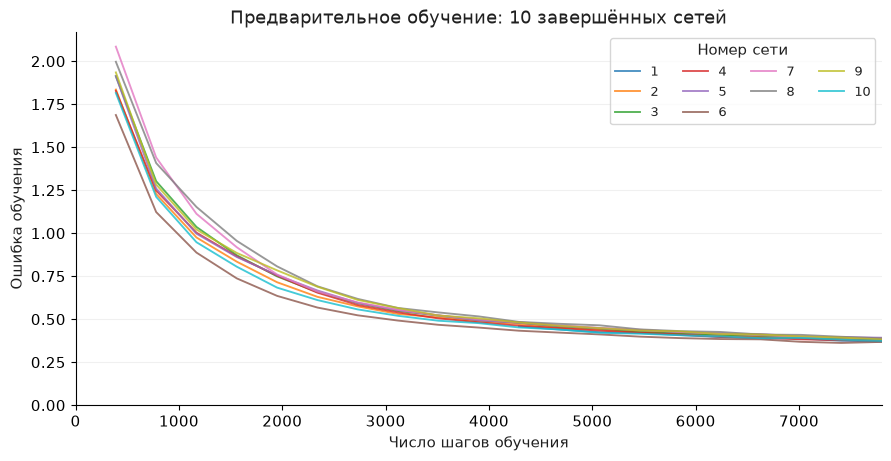

Ошибка обучения — среднее значение отрицательного логарифма вероятности правильного класса. Её снижение показывает, что сети обучаются, но само по себе не подтверждает пользу отбора. Первые 3 900 шагов первой сети были перенесены из прежнего запуска; отсутствующий участок её журнала не дорисован.

In [12]:
if ANALYSIS_READY:
    fig, ax = plt.subplots(figsize=(8.8,4.5), layout='constrained')
    for folder, rows in zip(folders, histories):
        ax.plot([r['step'] for r in rows], [r['train_loss'] for r in rows], lw=1.35, alpha=.8,
                label=str(int(folder.name[-2:])+1))
    ax.set(xlabel='Число шагов обучения', ylabel='Ошибка обучения',
           title=f'Предварительное обучение: {len(folders)} завершённых сетей', xlim=(0,7800), ylim=(0,None))
    ax.grid(axis='y',alpha=.18)
    ax.legend(title='Номер сети', ncol=4, fontsize=9, loc='upper right')
    save_figure(fig, 'preliminary_training')
    display(Markdown('Ошибка обучения — среднее значение отрицательного логарифма вероятности правильного класса. Её снижение показывает, что сети обучаются, но само по себе не подтверждает пользу отбора. Первые 3 900 шагов первой сети были перенесены из прежнего запуска; отсутствующий участок её журнала не дорисован.'))


### Распределение оценок изображений

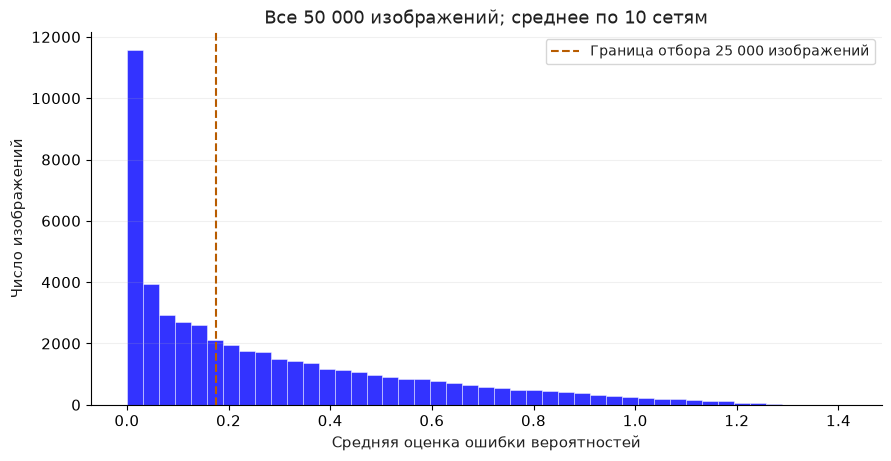

Оценка ошибки вероятностей — евклидово расстояние от предсказанных вероятностей классов до правильного ответа, записанного единицей у нужного класса и нулями у остальных. В статье эта оценка обозначается EL2N. Усредняются расстояния отдельных сетей, а не их вероятности. Гистограмма проверяет диапазон и неоднородность оценок; она не заменяет сравнение итоговых точностей.

In [13]:
if ANALYSIS_READY:
    fig, ax = plt.subplots(figsize=(8.8,4.5), layout='constrained')
    ax.hist(mean_scores, bins=np.linspace(0,np.sqrt(2),46), color=BLUE, alpha=.8, edgecolor='white', linewidth=.4)
    ax.set(xlabel='Средняя оценка ошибки вероятностей', ylabel='Число изображений',
           title=f'Все 50 000 изображений; среднее по {len(folders)} сетям')
    ax.grid(axis='y', alpha=.18)
    if len(folders) == 10:
        cutoff = np.sort(mean_scores)[25000]
        ax.axvline(cutoff, color=ORANGE, ls='--', label='Граница отбора 25 000 изображений')
        ax.legend(fontsize=10)
    save_figure(fig, 'score_distribution')
    display(Markdown('Оценка ошибки вероятностей — евклидово расстояние от предсказанных вероятностей классов до правильного ответа, записанного единицей у нужного класса и нулями у остальных. В статье эта оценка обозначается EL2N. Усредняются расстояния отдельных сетей, а не их вероятности. Гистограмма проверяет диапазон и неоднородность оценок; она не заменяет сравнение итоговых точностей.'))


### Согласованность оценок разных сетей

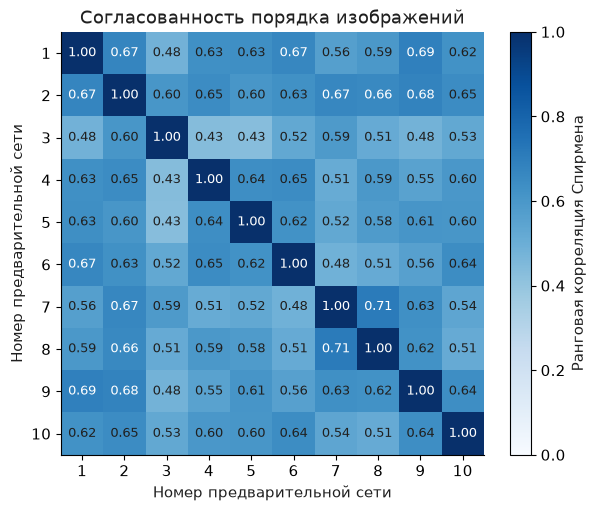

Ранговая корреляция Спирмена измеряет сходство двух упорядочений: единица означает одинаковый порядок, ноль — отсутствие линейной связи между рангами. Здесь сравниваются оценки разных предварительных сетей. Это проверка устойчивости оценивания, а не доказательство превосходства выбранной подвыборки.

In [14]:
if ANALYSIS_READY:
    def average_ranks(values):
        _, inverse, counts = np.unique(values, return_inverse=True, return_counts=True)
        return (np.cumsum(counts) - (counts+1)/2)[inverse]
    correlation = np.corrcoef(np.stack([average_ranks(row) for row in score_matrix]))
    fig, ax = plt.subplots(figsize=(6.3,5.0), layout='constrained')
    image = ax.imshow(correlation, vmin=0, vmax=1, cmap='Blues')
    ax.set(xticks=range(len(folders)), yticks=range(len(folders)),
           xticklabels=range(1,len(folders)+1), yticklabels=range(1,len(folders)+1),
           xlabel='Номер предварительной сети', ylabel='Номер предварительной сети',
           title='Согласованность порядка изображений')
    for row in range(len(folders)):
        for column in range(len(folders)):
            ax.text(column,row,f'{correlation[row,column]:.2f}',ha='center',va='center',fontsize=9,
                    color='white' if correlation[row,column]>.65 else '#202020')
    fig.colorbar(image, ax=ax, label='Ранговая корреляция Спирмена')
    save_figure(fig, 'score_agreement')
    display(Markdown('Ранговая корреляция Спирмена измеряет сходство двух упорядочений: единица означает одинаковый порядок, ноль — отсутствие линейной связи между рангами. Здесь сравниваются оценки разных предварительных сетей. Это проверка устойчивости оценивания, а не доказательство превосходства выбранной подвыборки.'))


### Примеры изображений с разными оценками

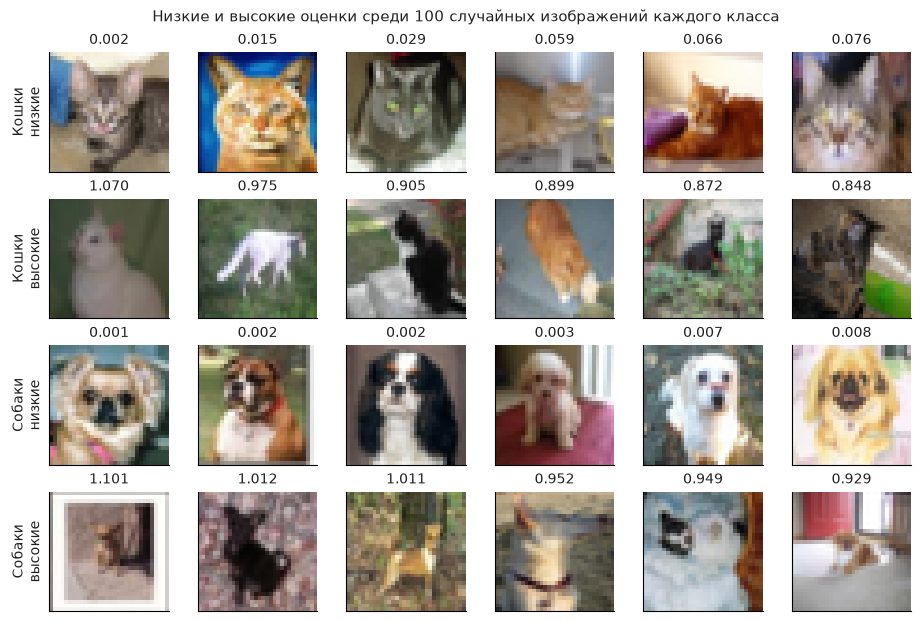

Число над изображением — его средняя оценка. Примеры отобраны по заранее определённому правилу из небольшой случайной выборки, без ручного выбора «удачных» иллюстраций. Высокая оценка может отражать сложность изображения или ошибочную метку; полезность такого изображения проверяется отдельным обучением.

In [15]:
if ANALYSIS_READY:
    sample = np.load(ROOT/'example_images.npz', allow_pickle=False)
    inverse_order = np.argsort(order)
    sample_scores = mean_scores[inverse_order[sample['indices']]]
    fig, axes = plt.subplots(4,6,figsize=(9.2,6.1), layout='constrained')
    for pair, (label, name) in enumerate([(3,'Кошки'), (5,'Собаки')]):
        indices = np.flatnonzero(sample['labels']==label)
        ranked = indices[np.argsort(sample_scores[indices], kind='stable')]
        for side, chosen in enumerate((ranked[:6], ranked[-6:][::-1])):
            row = 2*pair+side
            for column, index in enumerate(chosen):
                axes[row,column].imshow(sample['images'][index], interpolation='nearest')
                axes[row,column].set_title(f'{sample_scores[index]:.3f}',fontsize=10)
                axes[row,column].set_xticks([]); axes[row,column].set_yticks([])
            axes[row,0].set_ylabel(name+'\n'+('низкие' if side==0 else 'высокие'), fontsize=10)
    fig.suptitle('Низкие и высокие оценки среди 100 случайных изображений каждого класса',fontsize=11)
    save_figure(fig, 'image_examples')
    display(Markdown('Число над изображением — его средняя оценка. Примеры отобраны по заранее определённому правилу из небольшой случайной выборки, без ручного выбора «удачных» иллюстраций. Высокая оценка может отражать сложность изображения или ошибочную метку; полезность такого изображения проверяется отдельным обучением.'))


### Ход итогового обучения

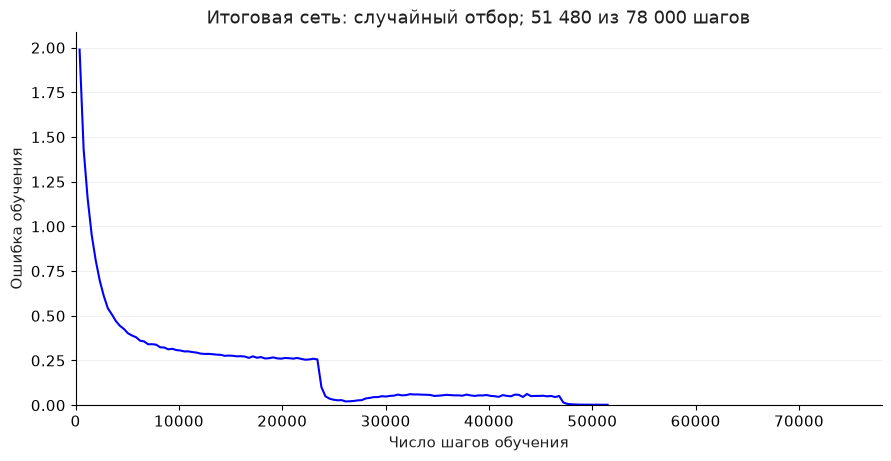

График показывает только выполненные шаги текущего обучения. Снижение ошибки на обучающих изображениях не является итоговой точностью на проверочной выборке.

In [16]:
if ANALYSIS_READY:
    progress = json.loads((ROOT/'progress.json').read_text(encoding='utf-8'))
    ongoing = ROOT/progress['run']
    if ongoing.name.startswith('evaluate_'):
        run_id, method = ongoing.name.split('_')[1:]
        expected = (np.sort(np.argsort(-mean_scores, kind='stable')[:25000]).astype(np.int32)
                    if method == 'el2n' else np.sort(np.random.default_rng(100000+int(run_id)).choice(50000,25000,replace=False)).astype(np.int32))
        assert np.array_equal(np.load(ongoing/'selected_sorted_indices.npy'), expected)
        if (ongoing/'selected_original_indices.npy').exists():
            assert np.array_equal(np.load(ongoing/'selected_original_indices.npy'), order[expected])
        current_history = history(ongoing)
        assert current_history[-1]['step'] == progress['step'] <= 78000
        fig, ax = plt.subplots(figsize=(8.8,4.5), layout='constrained')
        ax.plot([r['step'] for r in current_history], [r['train_loss'] for r in current_history], color=BLUE)
        ax.set(xlabel='Число шагов обучения', ylabel='Ошибка обучения', xlim=(0,78000), ylim=(0,None),
               title=f'Итоговая сеть: {"случайный отбор" if method == "random" else "отбор по оценке ошибки"}; {progress["step"]:,} из 78 000 шагов'.replace(',', ' '))
        ax.grid(axis='y',alpha=.18)
        save_figure(fig, 'training_progress')
        display(Markdown('График показывает только выполненные шаги текущего обучения. Снижение ошибки на обучающих изображениях не является итоговой точностью на проверочной выборке.'))


### Независимая проверка итоговых результатов

In [17]:
if ANALYSIS_READY:
    rows = []
    selected_el2n = np.sort(np.argsort(-mean_scores, kind='stable')[:25000]).astype(np.int32) if len(folders)==10 else None
    for path in sorted(ROOT.glob('evaluate_*/metrics.json')):
        record = json.loads(path.read_text())
        folder = path.parent
        assert record['run_id'] in range(10,14) and record['method'] in ('random','el2n')
        assert record['steps'] == 78000 and history(folder)[-1]['step'] == 78000
        indices = np.load(folder/'selected_sorted_indices.npy', allow_pickle=False)
        expected = (selected_el2n if record['method']=='el2n' else
            np.sort(np.random.default_rng(100000+record['run_id']).choice(50000,25000,replace=False)).astype(np.int32))
        assert expected is not None and np.array_equal(indices, expected)
        assert indices.shape == (25000,) and len(np.unique(indices)) == 25000
        assert np.array_equal(np.load(folder/'selected_original_indices.npy',allow_pickle=False),order[indices])
        assert record['class_counts']==np.bincount(labels[order[indices]],minlength=10).tolist()
        probabilities = np.load(folder/'test_probabilities.npy',allow_pickle=False)
        assert probabilities.shape==(10000,10) and np.isfinite(probabilities).all()
        assert probabilities.min()>=0 and probabilities.max()<=1 and np.allclose(probabilities.sum(axis=1),1,atol=1e-5)
        correct = int((probabilities.argmax(axis=1)==test_labels).sum())
        assert correct==record['correct'] and record['test_size']==10000
        assert abs(correct/10000-record['accuracy'])<1e-12
        assert record['model_seed']==42+424242*record['run_id'] and record['train_seed']==4242+424242*record['run_id']
        rows.append(record)
    actual = {(r['run_id'],r['method']) for r in rows}
    required = {(run,method) for run in range(10,14) for method in ('random','el2n')}
    complete = actual == required and len(rows)==8 and len(folders)==10
    statistics = []
    for method in ('random','el2n'):
        values = np.array([r['accuracy']*100 for r in rows if r['method']==method])
        if values.size:
            statistics.append(dict(method=method, count=len(values), mean=float(values.mean()),
                sample_std=float(values.std(ddof=1)) if len(values)>1 else None,
                p16=float(np.quantile(values,.16)), p84=float(np.quantile(values,.84))))
    off_diagonal = correlation[np.triu_indices(len(folders),1)]
    analysis = dict(complete=complete, preliminary_completed=len(folders), final_completed=len(rows),
        current_training=progress,
        score_mean=float(mean_scores.mean()),score_min=float(mean_scores.min()),score_max=float(mean_scores.max()),
        rank_correlation_min=float(off_diagonal.min()),rank_correlation_max=float(off_diagonal.max()),
        final_training_loss=[history(folder)[-1]['train_loss'] for folder in folders],
        statistics=statistics, verified_runs=rows, configuration_sha256=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest())
    (ROOT/'analysis.json').write_text(json.dumps(analysis,ensure_ascii=False,indent=2),encoding='utf-8')
    if not complete:
        display(Markdown(f'**Итоговых обучений завершено: {len(rows)} из 8.** Вывод о преимуществе отбора пока не сделан. Предварительные графики выше подтверждают выполнение подготовительного этапа, но не успешность воспроизведения основного результата.'))
    else:
        fig, ax = plt.subplots(figsize=(8.8,4.5), layout='constrained')
        for index, item in enumerate(statistics):
            values = [r['accuracy']*100 for r in rows if r['method']==item['method']]
            ax.scatter(index+np.linspace(-.08,.08,len(values)),values,color=[BLUE,ORANGE][index],s=48,zorder=3)
            ax.plot([index-.18,index+.18],[item['mean']]*2,color='black',lw=2)
            ax.vlines(index,item['p16'],item['p84'],color=[BLUE,ORANGE][index],lw=7,alpha=.25)
        ax.set(xticks=[0,1],xticklabels=['Случайный отбор','Отбор по оценке ошибки'],
            ylabel='Точность на 10 000 проверочных изображениях, %',title='Два способа отбора 25 000 изображений')
        ax.grid(axis='y',alpha=.18)
        save_figure(fig,'final_accuracy')
        display(Markdown('Точки показывают четыре повторения, чёрная черта — среднее, цветной отрезок — промежуток между 16-м и 84-м процентилями. Процентиль — значение, ниже которого находится указанная доля результатов. Такой промежуток описывает разброс повторений и не является доверительным интервалом.'))
        names={'random':'Случайный отбор','el2n':'Оценка ошибки'}
        table='| Способ | Среднее, % | Выборочное стандартное отклонение | 16-й процентиль | 84-й процентиль |\n|---|---:|---:|---:|---:|\n'
        for item in statistics:
            table+=f"| {names[item['method']]} | {item['mean']:.2f} | {item['sample_std']:.2f} | {item['p16']:.2f} | {item['p84']:.2f} |\n"
        display(Markdown(table))
        difference=statistics[1]['mean']-statistics[0]['mean']
        display(Markdown(f'Разность средних точностей: **{difference:+.2f} процентного пункта**. Это сравнение выбранной и случайной половин при одинаковом числе шагов. Обучение на всех 50 000 изображениях не выполнялось, поэтому сохранение точности относительно полного набора здесь не установлено.'))


**Итоговых обучений завершено: 0 из 8.** Вывод о преимуществе отбора пока не сделан. Предварительные графики выше подтверждают выполнение подготовительного этапа, но не успешность воспроизведения основного результата.

## Как понимать проверку

Сходство рисунков само по себе не доказывает воспроизводимость. Существенно направление и величина разности точностей после одинакового числа шагов: отбор по оценке ошибки должен сравниваться со случайной половиной на тех же проверочных изображениях. Все четыре повторения должны завершиться; точности пересчитываются из сохранённых вероятностей, а индексы и средние оценки проверяются независимо.

Без обучения на полном наборе нельзя проверить утверждение авторов о сохранении точности после удаления половины данных. Этот блокнот также не воспроизводит опыты на других наборах, перенос между архитектурами и исследования ошибок разметки.

Источники: [статья, версия 2](https://arxiv.org/abs/2107.07075v2), [код авторов](https://github.com/mansheej/data_diet), [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html). Рисунок 1 принадлежит авторам статьи; остальные графики строятся ячейками этого блокнота.